In [ ]:
!pip install -q -U google-genai pymongo pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.3.0 which is incompatible.


In [ ]:
!pip install -q -U google-genai pymongo

In [ ]:
#Configure the Gemini API key in Colab
from google.colab import userdata

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

if not GEMINI_API_KEY:
    raise ValueError("Gemini API key is missing!")

print("Gemini API key configured successfully!")


Gemini API key configured successfully!


In [ ]:
from google import genai
from google.genai import types

client = genai.Client(
    api_key=GEMINI_API_KEY,
    http_options=types.HttpOptions(
        timeout=60000
    )
)

MODEL_NAME = "gemini-3.5-flash"

print("Gemini client initialized successfully!")


Gemini client initialized successfully!


In [ ]:
response = client.models.generate_content(
    model=MODEL_NAME,
    contents="What is Artificial Intelligence?"
)

print(response.text)


**Artificial Intelligence (AI)** is a branch of computer science dedicated to creating systems capable of performing tasks that would typically require human intelligence. 

These tasks include things like **learning, reasoning, problem-solving, understanding language, recognizing patterns, and making decisions.**

Instead of simply following a rigid set of pre-written rules, AI systems use data to "learn" how to perform a task and improve their performance over time.

---

### How AI Works (In Simple Terms)
At its core, AI operates through three main steps:

1. **Input (Data):** The system takes in massive amounts of data (text, images, numbers, or audio).
2. **Processing (Algorithms):** The system uses mathematical rules (algorithms) to analyze the data, spot patterns, and draw conclusions.
3. **Output (Action or Prediction):** The system makes a decision, solves a problem, or creates something new based on what it learned.

---

### Key Subfields of AI
When people talk about AI toda

In [ ]:
MONGODB = userdata.get("MONGODB")

if not MONGODB:
    raise ValueError("MongoDB connection string is missing!")

print("MongoDB credentials loaded successfully!")


MongoDB credentials loaded successfully!


In [ ]:
from pymongo import MongoClient
from pymongo.server_api import ServerApi

mongo_client = MongoClient(
    MONGODB,
    server_api=ServerApi("1"),
    serverSelectionTimeoutMS=5000,
    connectTimeoutMS=5000,
    socketTimeoutMS=10000,
    timeoutMS=10000,
    retryWrites=True
)

# Test the database connection
mongo_client.admin.command("ping")

# Create database
db = mongo_client["GenAI_Monitoring"]

# Create collection
collection = db["api_usage_logs"]

print("MongoDB connected successfully!")
print("Database:", db.name)
print("Collection:", collection.name)


MongoDB connected successfully!
Database: GenAI_Monitoring
Collection: api_usage_logs


In [ ]:
import time
import uuid
import random
import pymongo

from datetime import datetime, timezone
from pymongo.errors import PyMongoError


In [ ]:
# Gemini 3.5 Flash standard paid-tier pricing
# USD per 1 million tokens

INPUT_PRICE = 0.30
OUTPUT_PRICE = 2.50

def calculate_cost(input_tokens, output_tokens):

    input_cost = (
        input_tokens * INPUT_PRICE / 1_000_000
    )

    output_cost = (
        output_tokens * OUTPUT_PRICE / 1_000_000
    )

    total_cost = input_cost + output_cost

    return total_cost


In [ ]:
def retry_delay(attempt):

    delay = min(2 ** (attempt - 1), 16)

    return delay + random.uniform(0, 1)


def is_temporary_error(error):

    status_code = getattr(
        error, "status_code",
        getattr(error, "code", None)
    )

    if status_code in [408, 429, 500, 502, 503, 504]:
        return True

    error_name = type(error).__name__.lower()

    temporary_errors = [
        "timeout",
        "connection",
        "temporarily"
    ]

    return any(
        word in error_name
        for word in temporary_errors
    )


In [ ]:
def save_log(record):

    for attempt in range(1, 4):

        try:

            with pymongo.timeout(10):

                collection.update_one(
                    {"_id": record["_id"]},
                    {"$setOnInsert": record},
                    upsert=True
                )

            print("Log saved in MongoDB!")
            return True

        except PyMongoError as error:

            print(
                f"MongoDB error: {error}"
            )

            if attempt == 3:
                print("Unable to save the log.")
                return False

            time.sleep(retry_delay(attempt))

    return False


In [ ]:
def ask_gemini(prompt):

    request_id = str(uuid.uuid4())

    MAX_RETRIES = 4

    for attempt in range(1, MAX_RETRIES + 1):

        start_time = time.perf_counter()

        input_tokens = 0
        output_tokens = 0
        total_tokens = 0

        response_text = ""
        error_message = None
        status = "failed"

        try:

            # Step 1: Send request to Gemini

            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt
            )

            # Step 2: Extract AI response

            response_text = response.text or ""

            # Step 3: Extract token information

            usage = response.usage_metadata

            if usage:

                input_tokens = (
                    usage.prompt_token_count or 0
                )

                output_tokens = (
                    usage.candidates_token_count or 0
                )

                total_tokens = (
                    usage.total_token_count or 0
                )

            # Step 4: Mark request as successful

            status = "success"

        except Exception as error:

            error_message = str(error)

            print(
                f"API attempt {attempt} failed: "
                f"{error_message}"
            )

        # Step 5: Measure latency

        latency = time.perf_counter() - start_time

        # Step 6: Calculate estimated cost

        estimated_cost = calculate_cost(
            input_tokens,
            output_tokens
        )

        # Step 7: Prepare MongoDB record

        log_record = {

            "_id": f"{request_id}_{attempt}",

            "request_id": request_id,

            "timestamp": datetime.now(timezone.utc),

            "model": MODEL_NAME,

            "prompt": prompt,

            "attempt": attempt,

            "input_tokens": input_tokens,

            "output_tokens": output_tokens,

            "total_tokens": total_tokens,

            "latency_seconds": round(latency, 3),

            "estimated_cost_usd": round(
                estimated_cost, 10
            ),

            "status": status,

            "error": error_message
        }

        # Step 8: Store the record in MongoDB

        save_log(log_record)

        # Step 9: Display the monitoring information

        print("\n========== API MONITORING ==========")

        print("Request ID:", request_id)

        print("Attempt:", attempt)

        print("Status:", status)

        print("Input Tokens:", input_tokens)

        print("Output Tokens:", output_tokens)

        print("Total Tokens:", total_tokens)

        print("Latency:", round(latency, 3), "seconds")

        print("Estimated Cost: $", estimated_cost)

        # Step 10: Return successful response

        if status == "success":

            print("\n========== GEMINI RESPONSE ==========")

            print(response_text)

            return response_text

        # Step 11: Retry only temporary failures

        if (
            attempt == MAX_RETRIES
            or not is_temporary_error(error)
        ):

            print("\nRequest failed permanently.")
            break

        wait_time = retry_delay(attempt)

        print(
            f"Retrying after {wait_time:.2f} seconds..."
        )

        time.sleep(wait_time)

    return None


In [ ]:
while True:

    prompt = input("\nEnter your question (or type exit): ")

    if prompt.lower() == "exit":
        print("Application stopped.")
        break

    if not prompt.strip():
        print("Please enter a valid question.")
        continue

    ask_gemini(prompt)



Enter your question (or type exit): What is LLM?
Log saved in MongoDB!

========== API MONITORING ==========
Request ID: 701fb712-4e78-47e8-9e93-0978ab32a653
Attempt: 1
Status: success
Input Tokens: 6
Output Tokens: 618
Total Tokens: 1438
Latency: 19.64 seconds
Estimated Cost: $ 0.0015467999999999999

========== GEMINI RESPONSE ==========
**LLM** stands for **Large Language Model**. 

It is a type of Artificial Intelligence (AI) designed to understand, process, and generate human text. LLMs are the technology behind modern AI chatbots like **ChatGPT**, **Google Gemini**, and **Claude**.

Here is a breakdown of what makes an LLM work:

---

### 1. What does the name mean?
* **Language Model:** A computer program trained to understand how human language works—grammar, context, vocabulary, and slang.
* **Large:** This refers to two things:
  1. **Massive Training Data:** They are trained on vast amounts of text from the internet, books, articles, code, and websites.
  2. **Vast Parameter

In [ ]:
records = list(
    collection.find(
        {},
        {"_id": 0}
    ).sort("timestamp", -1)
)

print("Total API attempts:", len(records))

for record in records:

    print("\n--------------------------")

    print("Model:", record["model"])

    print("Input Tokens:", record["input_tokens"])

    print("Output Tokens:", record["output_tokens"])

    print("Total Tokens:", record["total_tokens"])

    print("Latency:", record["latency_seconds"])

    print("Cost:", record["estimated_cost_usd"])

    print("Status:", record["status"])


Total API attempts: 3

--------------------------
Model: gemini-3.5-flash
Input Tokens: 6
Output Tokens: 618
Total Tokens: 1438
Latency: 19.64
Cost: 0.0015468
Status: success

--------------------------
Model: gemini-3.5-flash
Input Tokens: 5
Output Tokens: 665
Total Tokens: 1486
Latency: 8.755
Cost: 0.001664
Status: success

--------------------------
Model: gemini-3.5-flash
Input Tokens: 8
Output Tokens: 895
Total Tokens: 1984
Latency: 161.028
Cost: 0.0022399
Status: success


In [ ]:
import pandas as pd

records = list(
    collection.find({}, {"_id": 0})
)

df = pd.DataFrame(records)

if not df.empty:

    display(df)

else:

    print("No records found.")



/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


,attempt,error,estimated_cost_usd,input_tokens,latency_seconds,model,output_tokens,prompt,request_id,status,timestamp,total_tokens
0,1,None,0.002240,8,161.028,gemini-3.5-flash,895,What is a Large Language Model?,0bbccbc7-69e8-41fc-8879-2f18aef40f67,success,2026-11-13 06:34:43.711,1984
1,1,None,0.001664,5,8.755,gemini-3.5-flash,665,What is LLM,63e9d318-cfa4-4738-a396-f2beb92fcf8d,success,2026-11-16 09:16:13.080,1486
2,1,None,0.001547,6,19.640,gemini-3.5-flash,618,What is LLM?,701fb712-4e78-47e8-9e93-0978ab32a653,success,2026-11-16 09:23:06.479,1438


In [ ]:
pipeline = [

    {
        "$group": {

            "_id": None,

            "total_api_attempts": {
                "$sum": 1
            },

            "total_input_tokens": {
                "$sum": "$input_tokens"
            },

            "total_output_tokens": {
                "$sum": "$output_tokens"
            },

            "total_tokens": {
                "$sum": "$total_tokens"
            },

            "average_latency": {
                "$avg": "$latency_seconds"
            },

            "total_estimated_cost": {
                "$sum": "$estimated_cost_usd"
            }
        }
    }
]

result = list(
    collection.aggregate(pipeline)
)

if result:

    summary = result[0]

    print("Total API Attempts:",
          summary["total_api_attempts"])

    print("Total Input Tokens:",
          summary["total_input_tokens"])

    print("Total Output Tokens:",
          summary["total_output_tokens"])

    print("Total Tokens:",
          summary["total_tokens"])

    print("Average Latency:",
          round(summary["average_latency"], 3))

    print("Total Estimated Cost: $",
          summary["total_estimated_cost"])

else:

    print("No API usage data available.")


Total API Attempts: 3
Total Input Tokens: 19
Total Output Tokens: 2178
Total Tokens: 4908
Average Latency: 63.141
Total Estimated Cost: $ 0.0054507


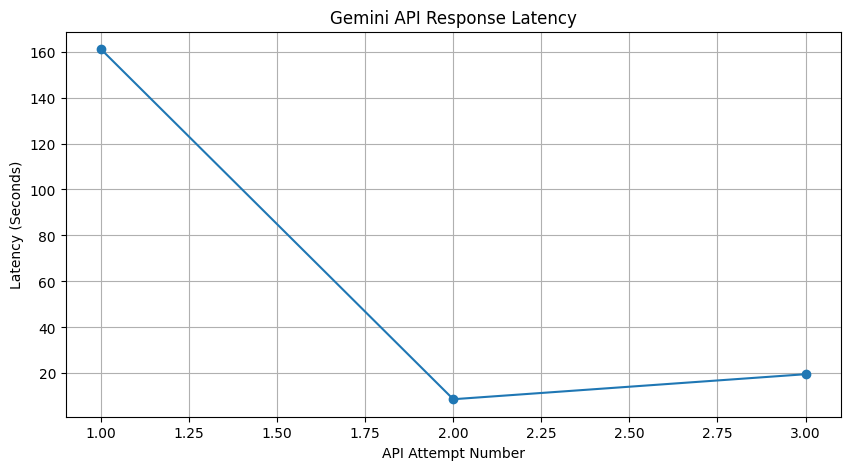

In [ ]:
import matplotlib.pyplot as plt

if not df.empty:

    plt.figure(figsize=(10, 5))

    plt.plot(
        range(1, len(df) + 1),
        df["latency_seconds"],
        marker="o"
    )

    plt.xlabel("API Attempt Number")

    plt.ylabel("Latency (Seconds)")

    plt.title("Gemini API Response Latency")

    plt.grid(True)

    plt.show()


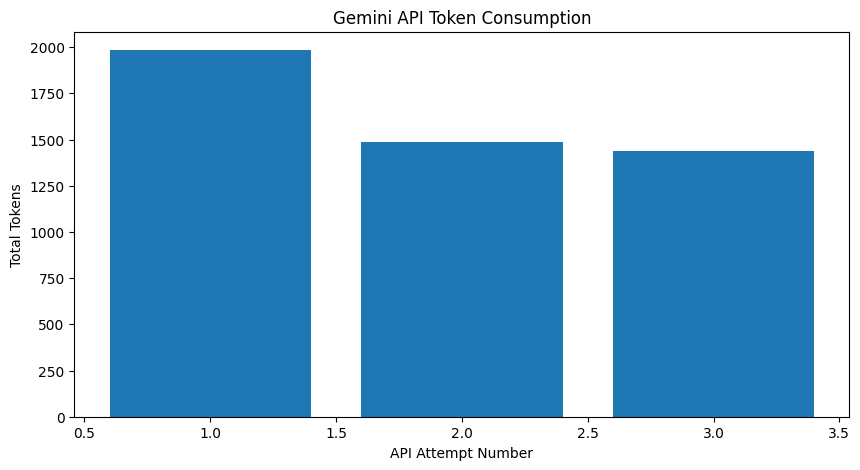

In [ ]:
if not df.empty:

    plt.figure(figsize=(10, 5))

    plt.bar(
        range(1, len(df) + 1),
        df["total_tokens"]
    )

    plt.xlabel("API Attempt Number")

    plt.ylabel("Total Tokens")

    plt.title("Gemini API Token Consumption")

    plt.show()


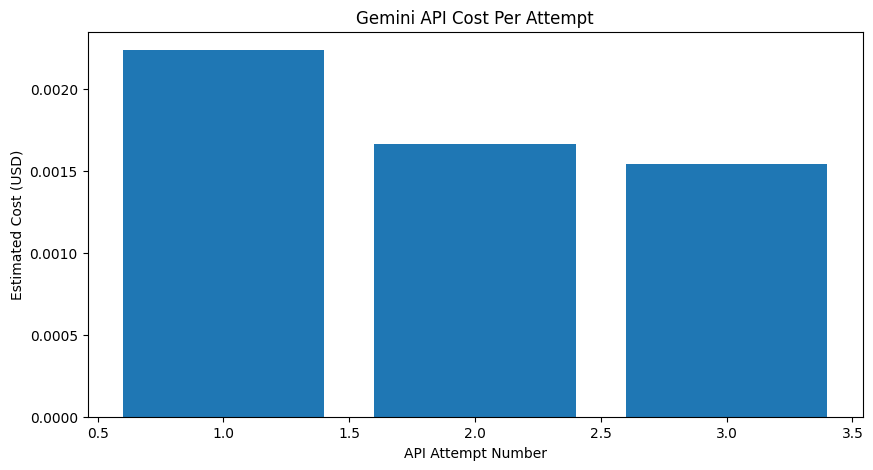

In [ ]:
if not df.empty:

    plt.figure(figsize=(10, 5))

    plt.bar(
        range(1, len(df) + 1),
        df["estimated_cost_usd"]
    )

    plt.xlabel("API Attempt Number")

    plt.ylabel("Estimated Cost (USD)")

    plt.title("Gemini API Cost Per Attempt")

    plt.show()
